# 08 · Registro de experimentos

Todos los intentos de mejorar el modelo, ronda a ronda, en un solo sitio y en formato compacto. Cada ronda tiene **qué se probó, qué salió y qué se decidió**, y sus tablas.

**Cómo leer los números:** son el error (RMSE) **relativo al modelo ingenuo** ("el precio dentro de *h* días será el de hoy"). **1 es el ingenuo, por debajo de 1 la red lo mejora** (verde) y por encima lo empeora (rojo).
- **Validación:** media de los años 2019-2023, con walk-forward. Todas las decisiones se toman con ella.
- **Test:** 2024-2026. Solo se mira para comprobar el modelo elegido; hasta ahora se ha usado dos veces (rondas 1 y 3).
- **red / ajustada:** la predicción de la red tal cual, o multiplicada por un peso entre 0 y 1 elegido en validación, que la acerca al ingenuo cuando la red aporta poco (peso 0 = el ingenuo).

Las tablas se leen de `reports/results/ronda_N/`, así que cada ronda nueva aparece al volver a ejecutar el notebook.

In [1]:
from IPython.display import display

from oil_forecast import experiment_log as log
from oil_forecast.config import RESULTS_DIR
from oil_forecast.plotting import set_style

set_style()
ROUNDS = sorted(int(p.name.split("_")[1]) for p in RESULTS_DIR.glob("ronda_*") if log.validation(int(p.name.split("_")[1])) is not None)
ROUNDS

[1, 2, 3, 4]

## Resumen

El mejor modelo de cada ronda en validación, por horizonte, y cómo le fue en el test cuando se hizo.

,1 semana · mejor en validación,1 semana · val,1 semana · test,3 meses · mejor en validación,3 meses · val,3 meses · test,1 año · mejor en validación,1 año · val,1 año · test
Ronda,,,,,,,,,
1,RNN simple,0.994,0.990,RNN simple,0.919,1.147,LSTM,0.980,0.947
2,RNN simple ajustada,0.995,—,Combinación ajustada,0.962,—,LSTM ajustada,0.985,—
3,RNN simple · lineal ajustada,0.995,0.992,RNN simple · top-5,0.901,1.066,LSTM · top-5 ajustada,0.979,0.931
4,RNN simple · top-5 + lineal ajustada,0.995,—,RNN simple · top-5 x2 semillas ajustada,0.938,—,LSTM · top-5 x2 semillas ajustada,0.977,—


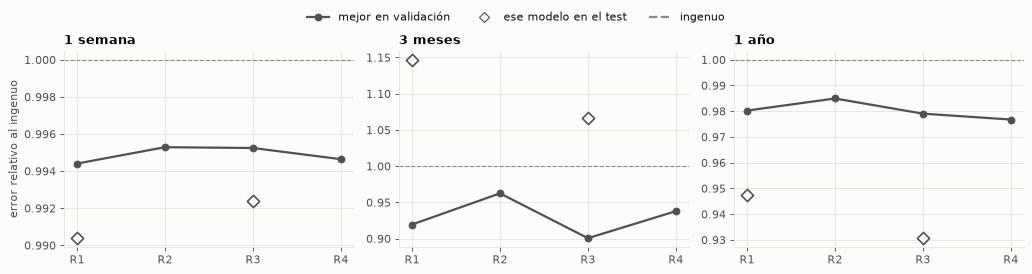

In [2]:
display(log.summary_table(ROUNDS))
log.evolution_plot(ROUNDS);

- **1 semana:** todas las rondas están en ~0,995. Es prácticamente el ingenuo y no ha cambiado nada.
- **3 meses:** es donde hay señal en validación (0,90-0,96), pero las dos veces que se ha mirado el test ha salido peor que el ingenuo. Parte de la mejora de validación era suerte (ronda 4).
- **1 año:** solo la LSTM ajustada baja un poco de 1 en validación (~0,98); en el test sale algo mejor (0,93-0,95).

## Ronda 1 · Primera búsqueda

- **Qué:** Optuna con 20 intentos por red y horizonte, ventana fija de 60 días. La ganadora de cada búsqueda se entrena con 5 semillas para el test.
- **Resultado:** la validación de esta ronda es la puntuación del propio ajuste, con **una sola semilla por intento**, así que es optimista. La RNN a 3 meses parecía muy buena (0,919) y en el test salió un 15 % peor que el ingenuo.
- **Decisión:** buscar en un espacio más amplio y medir la validación con 5 semillas.

In [3]:
display(log.validation_table(1), log.test_table(1))

,1 semana,3 meses,1 año
RNN simple,0.994,0.919,1.157
LSTM,0.997,0.952,0.980
GRU,0.998,0.946,1.095


,1 semana,3 meses,1 año
Ridge,1.001,1.068,0.923
RNN simple,0.990,1.147,0.955
LSTM,0.994,1.011,0.947
GRU,0.994,1.020,1.237


## Ronda 2 · Búsqueda más amplia, validación con 5 semillas

- **Qué:** 25 intentos por red y horizonte; se prueban ventanas de 20, 60 y 120 días y *learning rates* más bajos. La validación ya se mide con 5 semillas. Aparece la versión **ajustada**.
- **Resultado:** con 5 semillas los números son más realistas: a 3 meses la mejor queda en 0,96-0,97, y a 1 año solo la LSTM ajustada baja de 1.
- **⚠️ Problema detectado después:** cada red eligió su propia ventana, y el enunciado pide **la misma ventana para las tres**. Las rondas 2 a 4 heredan este fallo; se corrige en la ronda 5.
- **Decisión:** probar mejoras sobre esta búsqueda sin repetirla.

In [4]:
display(log.validation_table(2))

## Ronda 3 · Ensembles y otras ideas (test por segunda vez)

- **Qué:** tres variantes sobre la búsqueda de la ronda 2:
  - **top-5:** media de las 5 mejores configuraciones;
  - **recientes:** los años recientes pesan más al entrenar;
  - **lineal:** un modelo lineal en paralelo a la red.
- **Resultado en validación:** top-5 da el mayor salto del trabajo, la RNN a 3 meses en 0,901. *Recientes* empeora casi en todo y se descarta antes del test.
- **Test:** el modelo apuntado de antemano (RNN top-5 ajustada) sale 0,995 / 1,066 / 1,000. A 3 meses pierde, sobre todo en 2026, cuando el precio subió un 14 % y la red esperaba un +3 %.
- **Decisión:** no dar el trabajo por cerrado; seguir probando sobre validación y repetir el test más adelante.

In [5]:
display(log.validation_table(3), log.test_table(3))

## Ronda 4 · Más semillas, modelo lineal y menos variables

- **Qué:** top-5 con modelo lineal en paralelo, top-5 con el doble de semillas (10 modelos) y top-5 solo con las variables útiles, elegidas por importancia por permutación (desordenar cada variable y ver cuánto empeora el error).
- **Resultado:**
  - **Menos variables empeora en todo:** la RNN a 3 meses pasa a 1,022.
  - **Con el doble de semillas,** la RNN a 3 meses baja de 0,901 a 0,938: parte del 0,901 de la ronda 3 era suerte. La cifra realista ronda 0,93-0,94.
  - **top-5 + lineal a 3 meses** es la más estable: ningún año de validación es peor que el ingenuo.
- **Sin test.**

In [6]:
display(log.importance_table(4), log.validation_table(4))

,1 semana,3 meses,1 año
1,ret_brent (+0.012),vol_21 (+0.057),ratio_cobre_z252 (+0.054)
2,vol_63 (+0.004),basis_wti (+0.017),ret_gas_fut (+0.002)
3,ratio_cobre_z252 (+0.003),vol_63 (+0.016),ratio_oro_z252 (+0.002)
4,tipo_bce_chg_63 (+0.003),tipo_bce_chg_63 (+0.015),ret_brent (+0.001)
5,ret_wti_fut (+0.002),ratio_cobre_z252 (+0.013),ret_oro (+0.001)


### Curvas de aprendizaje (configuraciones de la ronda 4)

Una red de cada tipo y horizonte, entrenada con todo lo anterior a 2024 (`scripts/curvas.py`). La línea discontinua es el error de entrenamiento y la continua, el de validación (el último 15 % del periodo, del que la red no aprende).

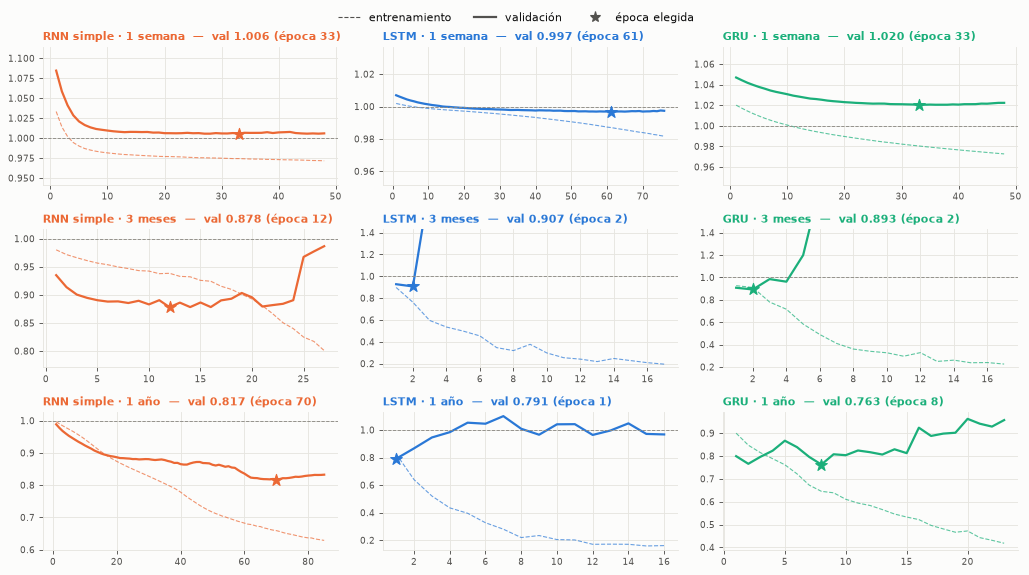

In [7]:
log.curves_grid(4);

- **1 semana:** la validación se queda pegada a 1 en las tres redes. No hay nada que aprender.
- **3 meses:** la **RNN simple** baja hasta una meseta de ~0,88 que dura unas 20 épocas: aprende de verdad. La **LSTM y la GRU** tocan su mejor punto en la época 2 y después memorizan (entrenamiento ~0,2, validación por encima de 2). Les sobra capacidad.
- **1 año:** las tres bajan de 1, pero el tramo de validación solo tiene unos 3 cambios anuales independientes y las curvas son muy ruidosas: no es fiable.

## Siguiente: ronda 5 (plan)

- **Misma ventana para las tres redes**, elegida probando 20, 60 y 120 días con las tres a la vez.
- **Nueva búsqueda** con el mismo número de intentos por red, cortando pronto los intentos que van mal (*pruning*), y con opciones más pequeñas o más regularizadas para la LSTM y la GRU.
- **Desempate por sencillez:** si dos configuraciones empatan dentro del ruido, gana la de menos parámetros.
- **Repetir las curvas** con las configuraciones nuevas y, cuando se decida, un último test con el modelo apuntado de antemano.